# Notebook 07. Validación e interpretabilidad del modelo – AccessGuard AI

## 1. Objetivo

Analizar e interpretar el comportamiento del modelo de clasificación de solicitudes de acceso IAM mediante SHAP (SHapley Additive Explanations), identificando las variables que más influyen en sus predicciones.

## 2. Alcance

Este análisis busca:

- Identificar las variables con mayor influencia en las predicciones del modelo.
- Interpretar cómo contribuyen las variables a aumentar o disminuir la puntuación de aprobación.
- Analizar las implicaciones de los resultados para el enfoque Zero Trust.
- Documentar los resultados y sus limitaciones.

## 3. Modelo analizado

Se utiliza el modelo LogReg ElasticNet previamente entrenado y almacenado en `models/model.joblib`.

El modelo recibe seis variables originales y utiliza un proceso de ingeniería de características que genera 29 variables transformadas.

## 4. Consideraciones metodológicas

- Se conserva el modelo entrenado, sin realizar una nueva optimización.
- Se utilizan datos del conjunto de entrenamiento.
- Se mantiene la separación por gerente (`MGR_ID`).
- No se utiliza el conjunto de reserva (holdout) para ajustar decisiones ni seleccionar el modelo.
- Los valores SHAP se interpretan en la escala de salida del clasificador (log-odds).
- La interpretación describe asociaciones utilizadas por el modelo, no relaciones causales.

In [10]:
# ============================================================
# 1. CONFIGURACIÓN Y CARGA DEL MODELO
# ============================================================

import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

# Localizar automáticamente la raíz del proyecto
CURRENT = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [CURRENT, *CURRENT.parents]
        if (p / "config" / "settings.py").exists()
        and (p / "models" / "model.joblib").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto AccessGuard AI."
    )

# Agregar las rutas del proyecto
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

from config import settings as S
from accessguard.data import drop_redundant

# Carpetas de resultados
REPORTS_DIR = ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

REPORTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# Cargar modelo definitivo
bundle = joblib.load(ROOT / "models" / "model.joblib")

pipeline = bundle["pipeline"]
feature_builder = pipeline.named_steps["features"]
model_pipeline = pipeline.named_steps["model"]

scaler = model_pipeline.named_steps["scale"]
classifier = model_pipeline.named_steps["clf"]

INPUT_COLUMNS = bundle["input_columns"]
FEATURE_NAMES = feature_builder.feature_names_

# Configuración visual
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Verificaciones
assert len(FEATURE_NAMES) == 29
assert classifier.coef_.shape[1] == 29

print("Configuración completada correctamente")
print("Raíz del proyecto:", ROOT)
print("Modelo:", bundle["model_name"])
print("Variables originales:", len(INPUT_COLUMNS))
print("Variables transformadas:", len(FEATURE_NAMES))
print("Clasificador:", type(classifier).__name__)
print("SHAP:", shap.__version__)
print("Carpeta de resultados:", FIGURES_DIR)

Configuración completada correctamente
Raíz del proyecto: /workspaces/laboratorio-avanzado-iam
Modelo: LogReg ElasticNet
Variables originales: 6
Variables transformadas: 29
Clasificador: LogisticRegression
SHAP: 0.54.1
Carpeta de resultados: /workspaces/laboratorio-avanzado-iam/reports/figures


In [11]:
# ============================================================
# 2. RECUPERACIÓN DEL CONJUNTO DE ENTRENAMIENTO
# ============================================================

# Leer datos originales
train_raw = pd.read_csv(S.TRAIN_PATH)

# Aplicar la limpieza original
train_clean = drop_redundant(train_raw)

# Reproducir la partición original por gerente
splitter = StratifiedGroupKFold(
    n_splits=round(1 / S.HOLDOUT_FRACTION),
    shuffle=True,
    random_state=S.SEED
)

train_idx, _ = next(
    splitter.split(
        train_clean,
        train_clean[S.TARGET],
        groups=train_clean[S.GROUP_COL]
    )
)

# Conservar únicamente el conjunto de entrenamiento
fit_part = train_clean.iloc[train_idx].copy()

# Separar variables y objetivo
X_train = fit_part[INPUT_COLUMNS].copy()
y_train = fit_part[S.TARGET].astype(int).to_numpy()

# Verificaciones
assert list(X_train.columns) == INPUT_COLUMNS
assert len(X_train) == len(y_train)
assert X_train[S.GROUP_COL].nunique() > 0

print("DATOS DE ENTRENAMIENTO RECUPERADOS")
print("-----------------------------------")
print("Solicitudes:", len(X_train))
print("Gerentes:", X_train[S.GROUP_COL].nunique())
print("Variables originales:", X_train.shape[1])
print("Solicitudes aprobadas:", int((y_train == 1).sum()))
print("Solicitudes denegadas:", int((y_train == 0).sum()))
print("Comprobaciones: correctas")

DATOS DE ENTRENAMIENTO RECUPERADOS
-----------------------------------
Solicitudes: 26215
Gerentes: 3360
Variables originales: 6
Solicitudes aprobadas: 24697
Solicitudes denegadas: 1518
Comprobaciones: correctas


In [12]:
# ============================================================
# 3. INGENIERÍA DE VARIABLES SIN FUGA DE INFORMACIÓN
# ============================================================

from sklearn.base import clone

# Copia independiente del constructor original
feature_builder_oof = clone(feature_builder)

# Generar variables con target encoding OOF
X_features_oof = feature_builder_oof.fit_transform(
    X_train,
    y_train
)

# Verificar nombres y dimensiones
assert X_features_oof.shape[1] == 29
assert list(X_features_oof.columns) == FEATURE_NAMES

# Aplicar el escalador original del modelo
X_scaled_oof = pd.DataFrame(
    scaler.transform(X_features_oof),
    columns=FEATURE_NAMES,
    index=X_train.index
)

# Comprobaciones
assert not X_scaled_oof.isna().any().any()
assert X_scaled_oof.shape == (len(X_train), 29)

print("INGENIERÍA DE VARIABLES COMPLETADA")
print("-----------------------------------")
print("Filas:", X_scaled_oof.shape[0])
print("Variables:", X_scaled_oof.shape[1])
print("Codificación OOF:", feature_builder_oof.n_splits, "pliegues")
print("Separación por grupo:", feature_builder_oof.group_col)
print("Semilla:", feature_builder_oof.seed)
print("Valores faltantes:", int(X_scaled_oof.isna().sum().sum()))
print("Comprobación de nombres: correcta")

INGENIERÍA DE VARIABLES COMPLETADA
-----------------------------------
Filas: 26215
Variables: 29
Codificación OOF: 5 pliegues
Separación por grupo: MGR_ID
Semilla: 42
Valores faltantes: 0
Comprobación de nombres: correcta


In [13]:
# ============================================================
# 4. CÁLCULO DE VALORES SHAP
# ============================================================

# Muestras reproducibles del entrenamiento
BACKGROUND_N = 200
EXPLAIN_N = 1500

X_background = X_scaled_oof.sample(
    n=min(BACKGROUND_N, len(X_scaled_oof)),
    random_state=42
)

X_explain = X_scaled_oof.sample(
    n=min(EXPLAIN_N, len(X_scaled_oof)),
    random_state=123
)

# Crear explicador para la regresión logística
explainer = shap.LinearExplainer(
    classifier,
    X_background.to_numpy()
)

# Calcular contribuciones SHAP
shap_result = explainer(X_explain.to_numpy())

# Objeto de explicación con nombres de variables
shap_values = shap.Explanation(
    values=shap_result.values,
    base_values=shap_result.base_values,
    data=X_explain.to_numpy(),
    feature_names=FEATURE_NAMES
)

# Resumen de comprobación
print("ANÁLISIS SHAP COMPLETADO")
print("------------------------")
print("Modelo:", bundle["model_name"])
print("Muestra de referencia:", X_background.shape[0])
print("Solicitudes explicadas:", X_explain.shape[0])
print("Variables:", shap_values.values.shape[1])
print("Dimensiones SHAP:", shap_values.values.shape)
print("Escala de explicación: log-odds")

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


ANÁLISIS SHAP COMPLETADO
------------------------
Modelo: LogReg ElasticNet
Muestra de referencia: 200
Solicitudes explicadas: 1500
Variables: 29
Dimensiones SHAP: (1500, 29)
Escala de explicación: log-odds


In [14]:
# ============================================================
# 4. CÁLCULO DE VALORES SHAP
# ============================================================

BACKGROUND_N = 200
EXPLAIN_N = 1500

X_background = X_scaled_oof.sample(
    n=BACKGROUND_N,
    random_state=42
)

X_explain = X_scaled_oof.sample(
    n=EXPLAIN_N,
    random_state=123
)

# Definir explícitamente los 200 registros de referencia
masker = shap.maskers.Independent(
    X_background.to_numpy(),
    max_samples=BACKGROUND_N
)

# Crear explicador
explainer = shap.LinearExplainer(
    classifier,
    masker
)

# Calcular SHAP
shap_result = explainer(X_explain.to_numpy())

shap_values = shap.Explanation(
    values=shap_result.values,
    base_values=shap_result.base_values,
    data=X_explain.to_numpy(),
    feature_names=FEATURE_NAMES
)

print("ANÁLISIS SHAP COMPLETADO")
print("Muestra de referencia:", BACKGROUND_N)
print("Solicitudes explicadas:", EXPLAIN_N)
print("Variables:", len(FEATURE_NAMES))
print("Dimensiones SHAP:", shap_values.values.shape)

ANÁLISIS SHAP COMPLETADO
Muestra de referencia: 200
Solicitudes explicadas: 1500
Variables: 29
Dimensiones SHAP: (1500, 29)


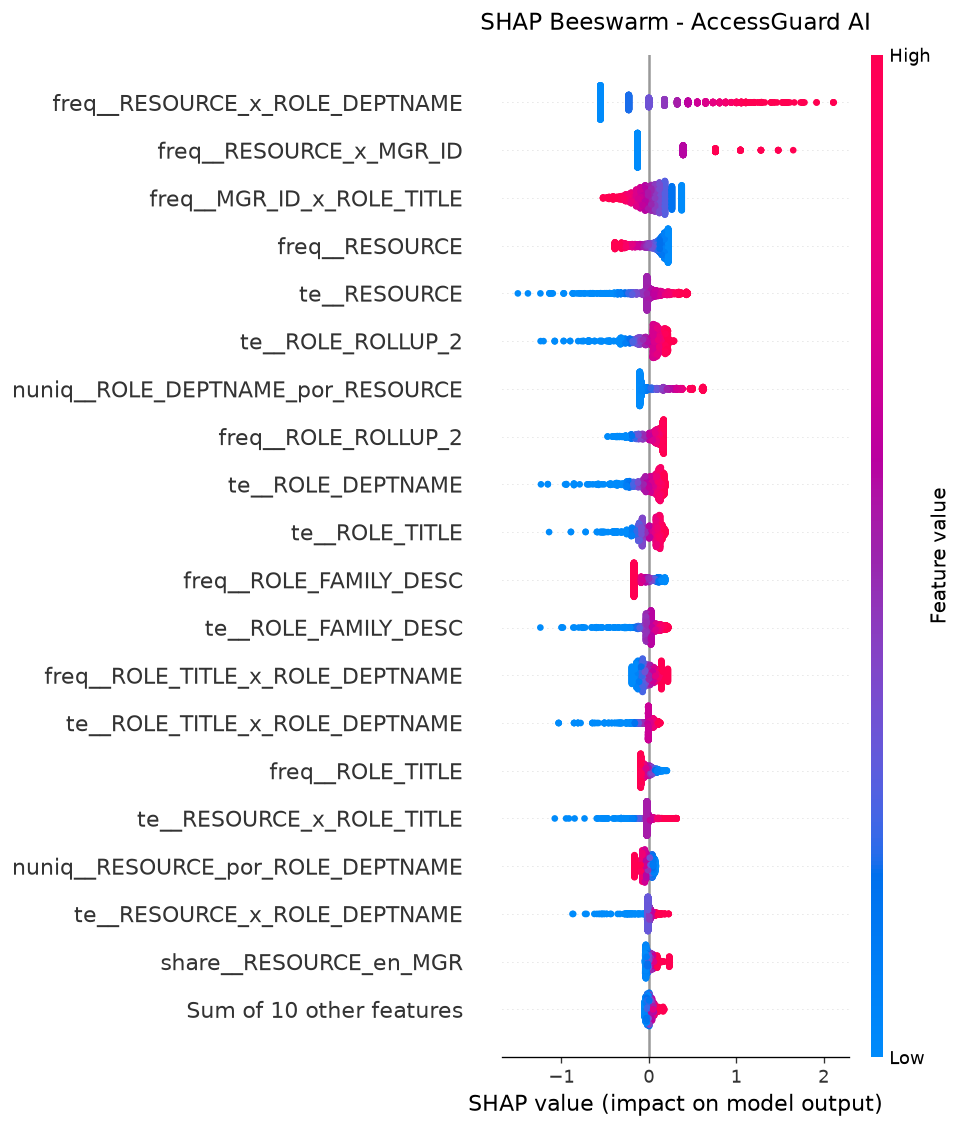

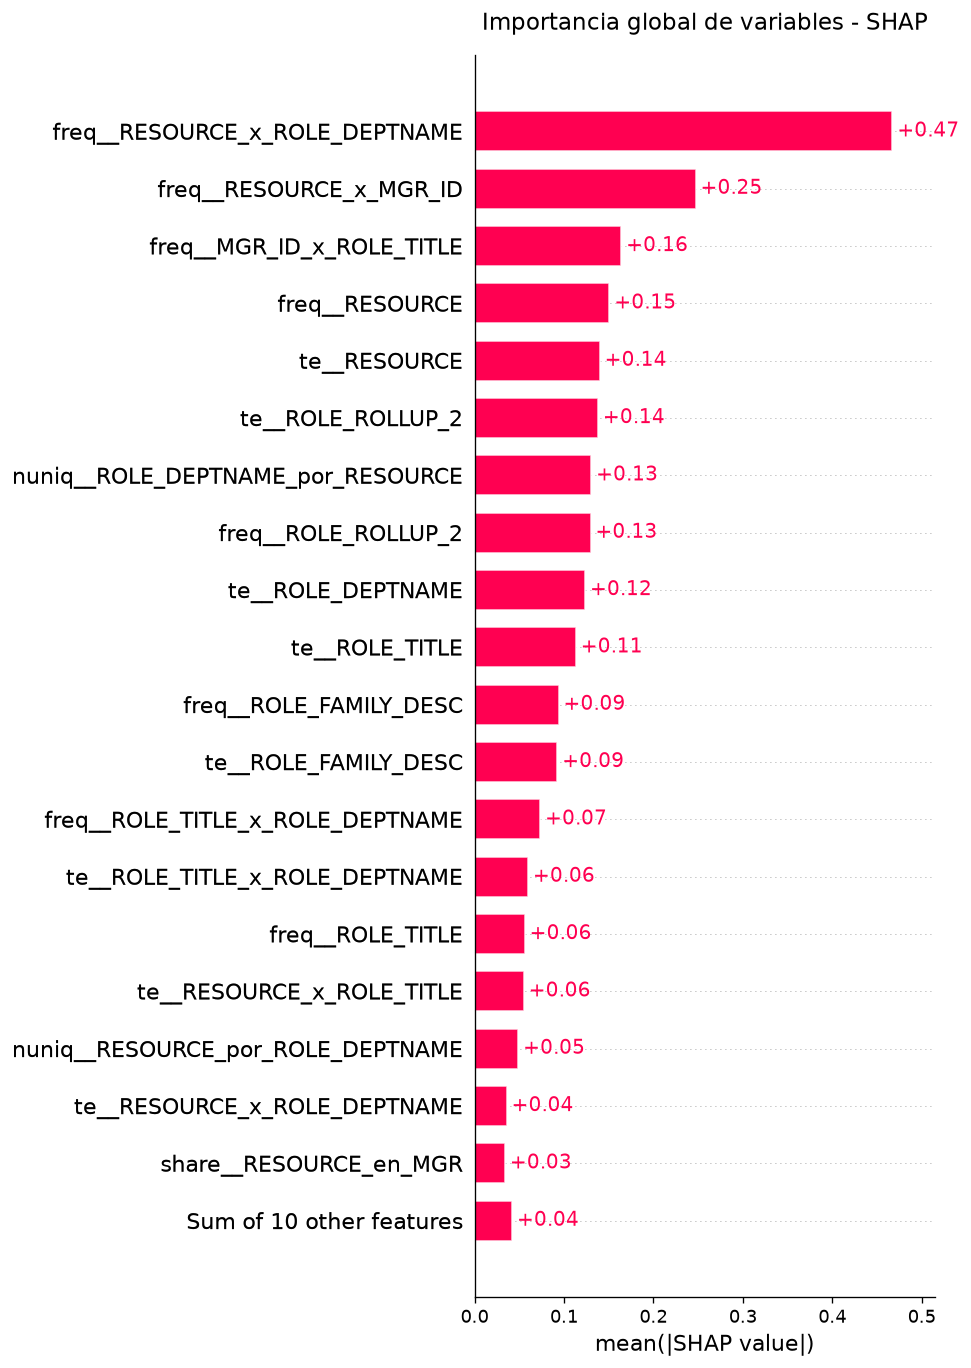

TOP 5 VARIABLES MÁS IMPORTANTES


,variable,mean_abs_shap,mean_shap
0,freq__RESOURCE_x_ROLE_DEPTNAME,0.467166,-0.048209
1,freq__RESOURCE_x_MGR_ID,0.247123,0.064870
2,freq__MGR_ID_x_ROLE_TITLE,0.163957,-0.014068
3,freq__RESOURCE,0.150728,0.007681
4,te__RESOURCE,0.139927,0.004385



ARCHIVOS GENERADOS:
/workspaces/laboratorio-avanzado-iam/reports/figures/shap_summary.png
/workspaces/laboratorio-avanzado-iam/reports/figures/shap_importance.png
/workspaces/laboratorio-avanzado-iam/reports/07_shap_importance.csv


In [15]:
# ============================================================
# 5. GRÁFICAS DE INTERPRETABILIDAD SHAP
# ============================================================

# 1. Gráfico Beeswarm
plt.figure(figsize=(11, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.gca().set_title(
    "SHAP Beeswarm - AccessGuard AI",
    fontsize=14,
    pad=15
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 2. Gráfico de importancia global
plt.figure(figsize=(11, 8))

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.gca().set_title(
    "Importancia global de variables - SHAP",
    fontsize=14,
    pad=15
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 3. Calcular importancia promedio
importance_df = pd.DataFrame({
    "variable": FEATURE_NAMES,
    "mean_abs_shap": np.abs(shap_values.values).mean(axis=0),
    "mean_shap": shap_values.values.mean(axis=0)
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

# Guardar resultados
importance_df.to_csv(
    REPORTS_DIR / "07_shap_importance.csv",
    index=False
)

# Mostrar las cinco variables más importantes
top5_features = importance_df.head(5)

print("TOP 5 VARIABLES MÁS IMPORTANTES")
display(top5_features.round(6))

print("\nARCHIVOS GENERADOS:")
print(FIGURES_DIR / "shap_summary.png")
print(FIGURES_DIR / "shap_importance.png")
print(REPORTS_DIR / "07_shap_importance.csv")

## 6. Interpretación de las gráficas SHAP

En esta sección buscamos entender qué variables tienen mayor influencia en las decisiones del modelo y cómo participan en la predicción de una solicitud de acceso.

### 6.1. Gráfica SHAP Beeswarm

Esta gráfica nos permite ver cómo influye cada variable en las predicciones:

- Los puntos representan solicitudes de acceso.
- Los valores hacia la derecha indican que la variable empuja la predicción hacia la aprobación.
- Los valores hacia la izquierda indican que la empuja hacia la denegación.
- El color rojo representa valores altos de la variable y el azul valores bajos.

En nuestra gráfica podemos observar que las combinaciones entre el recurso solicitado y el departamento, así como entre el recurso y el gerente, tienen una influencia importante en las decisiones del modelo.

### 6.2. Importancia global de las variables

Esta gráfica organiza las variables desde la que más influye hasta la que menos influye en las predicciones.

Las cinco variables con mayor importancia fueron:

1. Frecuencia de la combinación recurso - departamento.
2. Frecuencia de la combinación recurso - gerente.
3. Frecuencia de la combinación gerente - cargo.
4. Frecuencia del recurso solicitado.
5. Tendencia histórica de aprobación del recurso.

Esto nos muestra que el modelo no toma sus decisiones considerando únicamente el recurso solicitado, sino también los patrones asociados a quién lo solicita y a qué área o cargo pertenece.

### 6.3. Hallazgo principal

El resultado más destacado es que la combinación entre el recurso y el departamento tiene una influencia considerablemente mayor que las demás variables.

Esto sugiere que los patrones históricos de solicitudes dentro de cada departamento son importantes para el modelo.

Desde el enfoque IAM y Zero Trust, estos resultados ayudan a comprender qué información está utilizando el modelo para apoyar las decisiones de acceso. Sin embargo, la importancia de una variable no significa que por sí sola determine si un acceso es legítimo o seguro.

In [16]:
# ============================================================
# 7. COMPROBACIÓN Y ANÁLISIS DE LAS CONTRIBUCIONES SHAP
# ============================================================

# Comprobar que la suma de SHAP reconstruye la salida del modelo
model_scores = classifier.decision_function(X_explain.to_numpy())

shap_reconstructed = (
    shap_values.base_values
    + shap_values.values.sum(axis=1)
)

max_difference = np.max(
    np.abs(model_scores - shap_reconstructed)
)

print("COMPROBACIÓN DE EXPLICABILIDAD")
print("--------------------------------")
print("Diferencia máxima:", max_difference)
print("Salida del modelo reconstruida con SHAP:",
      "Correctamente" if max_difference < 1e-5 else "Revisar")


# Analizar la dirección de las contribuciones
values = shap_values.values

direction_df = pd.DataFrame({
    "variable": FEATURE_NAMES,
    "importancia_media": np.abs(values).mean(axis=0),
    "contribucion_media": values.mean(axis=0),
    "contribuciones_hacia_aprobacion_pct":
        (values > 0).mean(axis=0) * 100,
    "contribuciones_hacia_denegacion_pct":
        (values < 0).mean(axis=0) * 100
})

direction_df = direction_df.sort_values(
    "importancia_media",
    ascending=False
).reset_index(drop=True)

top5_direction = direction_df.head(5)

print("\nTOP 5 VARIABLES Y DIRECCIÓN DE SUS CONTRIBUCIONES")
display(top5_direction.round(4))

COMPROBACIÓN DE EXPLICABILIDAD
--------------------------------
Diferencia máxima: 1.7763568394002505e-15
Salida del modelo reconstruida con SHAP: Correctamente

TOP 5 VARIABLES Y DIRECCIÓN DE SUS CONTRIBUCIONES


,variable,importancia_media,contribucion_media,contribuciones_hacia_aprobacion_pct,contribuciones_hacia_denegacion_pct
0,freq__RESOURCE_x_ROLE_DEPTNAME,0.4672,-0.0482,43.2667,56.7333
1,freq__RESOURCE_x_MGR_ID,0.2471,0.0649,29.0000,71.0000
2,freq__MGR_ID_x_ROLE_TITLE,0.1640,-0.0141,44.0000,56.0000
3,freq__RESOURCE,0.1507,0.0077,58.4000,41.6000
4,te__RESOURCE,0.1399,0.0044,55.8000,44.2000


## 8. Validación e interpretación de resultados

### 8.1. Comprobación del análisis SHAP

Se verificó que la suma del valor base y las contribuciones SHAP reconstruye la salida del clasificador. La diferencia máxima fue prácticamente cero (1.78 × 10⁻¹⁵), lo que confirma la consistencia matemática de la explicación.

### 8.2. Variables más influyentes

Las cinco variables con mayor importancia fueron:

1. **Frecuencia del recurso por departamento:** es la variable con mayor influencia en las predicciones.
2. **Frecuencia del recurso por gerente:** representa la frecuencia histórica de solicitudes de un recurso asociadas a un gerente.
3. **Frecuencia del gerente por cargo:** refleja los patrones de solicitudes asociados a la combinación entre gerente y cargo.
4. **Frecuencia del recurso:** representa qué tan frecuente es la solicitud de un recurso dentro de los datos de entrenamiento.
5. **Codificación histórica del recurso:** representa la tendencia histórica de aprobación asociada al recurso.

### 8.3. Dirección de las contribuciones

Los resultados muestran que las variables pueden influir en diferentes direcciones dependiendo de cada solicitud.

Una contribución SHAP positiva empuja la predicción hacia la aprobación, mientras que una contribución negativa la empuja hacia la denegación.

Por ejemplo, la frecuencia del recurso por departamento presenta una contribución promedio negativa (-0.0482), mientras que la frecuencia del recurso por gerente presenta una contribución promedio positiva (0.0649).

Esto demuestra que no basta con identificar qué variable tiene mayor importancia: también es necesario analizar cómo participa en cada predicción.

### 8.4. Hallazgo general

El modelo da una importancia considerable a los patrones históricos relacionados con los recursos solicitados, los gerentes, los cargos y los departamentos.

Estos resultados permiten conocer qué información está utilizando el modelo para apoyar las decisiones de acceso. Sin embargo, estas relaciones no representan causas ni garantizan que una solicitud sea segura o indebida.

Por esta razón, los resultados deben utilizarse como apoyo a la supervisión y revisión humana, manteniendo los principios de mínimo privilegio y Zero Trust.

## 9. Zonas operativas de decisión – Zero Trust

El modelo utiliza la probabilidad de aprobación para organizar las solicitudes de acceso en un proceso de decisión y revisión.

Para esto se identifican tres zonas operativas:

### Zona 1. Autoaprobación

Corresponde a las solicitudes cuya probabilidad de aprobación supera el umbral estricto establecido en el modelo (0.9809057).

Estas solicitudes pueden ser aprobadas automáticamente según la regla definida. Sin embargo, esta decisión no garantiza que el acceso esté libre de riesgo, por lo que se requiere seguimiento y monitoreo.

### Zona 2. Revisión prioritaria

Corresponde a las solicitudes que no superan el umbral y que presentan las puntuaciones más bajas de probabilidad de aprobación.

El sistema las ubica primero en la cola de revisión, para que los analistas IAM puedan atender inicialmente los casos que requieren mayor atención.

### Zona 3. Revisión manual ordinaria

Incluye las demás solicitudes que no fueron aprobadas automáticamente y que permanecen pendientes de revisión humana.

Estas solicitudes continúan bajo supervisión del analista IAM. El modelo no las deniega automáticamente.

### Consideración operativa

El sistema implementa dos decisiones: aprobación automática y revisión humana. Las zonas de revisión prioritaria y ordinaria son una propuesta de organización de la cola de trabajo, no dos clases adicionales predichas por el modelo.

La separación entre ambas zonas debe definirse de acuerdo con la capacidad del equipo IAM y sus criterios de atención.

In [17]:
# ============================================================
# 10. REGLAS OPERATIVAS DEL MODELO
# ============================================================

operational_rules = {
    "model": bundle["model_name"],
    "threshold_auto_approval": float(bundle["t_auto_strict"]),
    "confidence_reference": float(bundle["t_confidence"]),
    "decision_1": "Autoaprobar si p_approve > threshold_auto_approval",
    "decision_2": "Enviar a revisión humana si p_approve <= threshold_auto_approval",
    "review_priority": "Orden ascendente de p_approve",
    "automatic_denial": False,
    "review_zones": {
        "priority": "Primeras solicitudes de la cola según capacidad IAM",
        "ordinary": "Solicitudes restantes de la cola manual"
    },
    "priority_cutoff_defined_in_model": False
}

print("REGLAS OPERATIVAS")
print("-----------------")

for key, value in operational_rules.items():
    print(f"{key}: {value}")

REGLAS OPERATIVAS
-----------------
model: LogReg ElasticNet
threshold_auto_approval: 0.9809057434648595
confidence_reference: 0.98
decision_1: Autoaprobar si p_approve > threshold_auto_approval
decision_2: Enviar a revisión humana si p_approve <= threshold_auto_approval
review_priority: Orden ascendente de p_approve
automatic_denial: False
review_zones: {'priority': 'Primeras solicitudes de la cola según capacidad IAM', 'ordinary': 'Solicitudes restantes de la cola manual'}
priority_cutoff_defined_in_model: False


In [18]:
# ============================================================
# 11. GENERACIÓN DEL INFORME FINAL SHAP
# ============================================================

import json

# Preparar las cinco variables principales
top5_records = []

for _, row in direction_df.head(5).iterrows():
    top5_records.append({
        "variable": str(row["variable"]),
        "importancia_media_absoluta": float(row["importancia_media"]),
        "contribucion_media": float(row["contribucion_media"]),
        "contribuciones_hacia_aprobacion_pct": float(
            row["contribuciones_hacia_aprobacion_pct"]
        ),
        "contribuciones_hacia_denegacion_pct": float(
            row["contribuciones_hacia_denegacion_pct"]
        )
    })

# Construir informe
shap_report = {
    "project": "AccessGuard AI",
    "analysis": "Interpretabilidad del modelo mediante SHAP",

    "model": {
        "name": bundle["model_name"],
        "type": "LogisticRegression ElasticNet",
        "original_variables": INPUT_COLUMNS,
        "transformed_variables": FEATURE_NAMES
    },

    "training_data": {
        "requests": int(len(X_train)),
        "managers": int(X_train[S.GROUP_COL].nunique()),
        "approved": int((y_train == 1).sum()),
        "denied": int((y_train == 0).sum())
    },

    "shap_analysis": {
        "method": "LinearExplainer",
        "masker": "Independent",
        "background_samples": int(len(X_background)),
        "explained_requests": int(len(X_explain)),
        "number_of_variables": int(len(FEATURE_NAMES)),
        "output_scale": "Log-odds for ACTION=1 (approval)",
        "feature_importance_method": "Mean absolute SHAP value",
        "max_additivity_error": float(max_difference)
    },

    "top_5_features": top5_records,

    "decision_policy": operational_rules,

    "artifacts": {
        "beeswarm": "reports/figures/shap_summary.png",
        "importance_chart": "reports/figures/shap_importance.png",
        "importance_csv": "reports/07_shap_importance.csv"
    },

    "limitations": [
        "SHAP describes model contributions, not causal relationships.",
        "Feature importance does not establish whether an access is safe or unsafe.",
        "The analysis uses out-of-fold target encoding grouped by MGR_ID.",
        "The holdout was not used for this SHAP analysis.",
        "The priority and ordinary review zones are operational subdivisions, not separate model predictions.",
        "The Independent masker treats transformed features independently; correlations between engineered features may affect interpretation."
    ]
}

# Guardar JSON
json_path = REPORTS_DIR / "07_shap_analysis.json"

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(shap_report, file, indent=4, ensure_ascii=False)

# Guardar también la tabla de dirección de contribuciones
direction_df.to_csv(
    REPORTS_DIR / "07_shap_direction.csv",
    index=False
)

print("INFORME SHAP GENERADO CORRECTAMENTE")
print("-----------------------------------")
print("Informe:", json_path)
print("Variables documentadas:", len(top5_records))
print("Tabla de contribuciones:", REPORTS_DIR / "07_shap_direction.csv")

INFORME SHAP GENERADO CORRECTAMENTE
-----------------------------------
Informe: /workspaces/laboratorio-avanzado-iam/reports/07_shap_analysis.json
Variables documentadas: 5
Tabla de contribuciones: /workspaces/laboratorio-avanzado-iam/reports/07_shap_direction.csv


In [19]:
# ============================================================
# 12. VERIFICACIÓN DE ENTREGABLES
# ============================================================

import json

expected_files = [
    ROOT / "notebooks/07_explicabilidad_shap_validacion.ipynb",
    REPORTS_DIR / "07_shap_analysis.json",
    REPORTS_DIR / "07_shap_importance.csv",
    REPORTS_DIR / "07_shap_direction.csv",
    FIGURES_DIR / "shap_summary.png",
    FIGURES_DIR / "shap_importance.png"
]

print("VERIFICACIÓN DE ARCHIVOS")
print("------------------------")

for file in expected_files:
    exists = file.exists()
    size = file.stat().st_size if exists else 0

    print(
        f"{'OK' if exists else 'FALTA'} | "
        f"{file.relative_to(ROOT)} | "
        f"{size:,} bytes"
    )

# Comprobar que el JSON sea válido
with open(REPORTS_DIR / "07_shap_analysis.json", encoding="utf-8") as f:
    saved_report = json.load(f)

assert len(saved_report["top_5_features"]) == 5
assert saved_report["shap_analysis"]["number_of_variables"] == 29

print("\nJSON válido y legible.")
print("Cinco variables documentadas.")
print("29 variables explicadas.")

VERIFICACIÓN DE ARCHIVOS
------------------------
OK | notebooks/07_explicabilidad_shap_validacion.ipynb | 439,707 bytes
OK | reports/07_shap_analysis.json | 5,145 bytes
OK | reports/07_shap_importance.csv | 1,730 bytes
OK | reports/07_shap_direction.csv | 2,373 bytes
OK | reports/figures/shap_summary.png | 286,857 bytes
OK | reports/figures/shap_importance.png | 235,012 bytes

JSON válido y legible.
Cinco variables documentadas.
29 variables explicadas.


In [20]:
# ============================================================
# 13. VALIDACIÓN CRUZADA Y PREDICCIONES OOF
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

# Utilizar los hiperparámetros del modelo definitivo
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=S.SEED
)

# Espacio para guardar una predicción por solicitud
oof_prob = np.full(len(X_train), np.nan)
fold_assignment = np.full(len(X_train), -1)

# Validación cruzada por gerente
for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train, groups=X_train[S.GROUP_COL]),
    start=1
):
    # Copiar el modelo definitivo, sin modificar el original
    fold_model = clone(bundle["pipeline"])

    # Entrenar con cuatro pliegues
    fold_model.fit(
        X_train.iloc[train_idx],
        y_train[train_idx]
    )

    # Predecir solamente el pliegue no utilizado para entrenar
    oof_prob[valid_idx] = fold_model.predict_proba(
        X_train.iloc[valid_idx]
    )[:, 1]

    fold_assignment[valid_idx] = fold

    print(
        f"Pliegue {fold}/5 completado | "
        f"Entrenamiento: {len(train_idx)} | "
        f"Validación: {len(valid_idx)}"
    )

# Verificaciones
assert np.isfinite(oof_prob).all()
assert (fold_assignment >= 1).all()
assert np.all((oof_prob >= 0) & (oof_prob <= 1))

# Tabla de resultados OOF
oof_results = pd.DataFrame({
    "ACTION": y_train,
    "probabilidad_aprobacion": oof_prob,
    "pliegue": fold_assignment
}, index=X_train.index)

print("\nVALIDACIÓN OOF COMPLETADA")
print("Solicitudes:", len(oof_results))
print("Pliegues:", oof_results["pliegue"].nunique())
print("Predicciones faltantes:", int(oof_results["probabilidad_aprobacion"].isna().sum()))

display(oof_results.head())

Pliegue 1/5 completado | Entrenamiento: 20972 | Validación: 5243
Pliegue 2/5 completado | Entrenamiento: 20976 | Validación: 5239
Pliegue 3/5 completado | Entrenamiento: 20968 | Validación: 5247
Pliegue 4/5 completado | Entrenamiento: 20972 | Validación: 5243
Pliegue 5/5 completado | Entrenamiento: 20972 | Validación: 5243

VALIDACIÓN OOF COMPLETADA
Solicitudes: 26215
Pliegues: 5
Predicciones faltantes: 0


,ACTION,probabilidad_aprobacion,pliegue
1,1,0.859851,4
2,1,0.688644,4
3,1,0.890666,5
5,0,0.672292,1
7,1,0.814760,4


MÉTRICAS DE VALIDACIÓN Y CALIBRACIÓN OOF
----------------------------------------
Brier Score: 0.060791
Brier baseline: 0.054553
Brier Skill Score: -0.114354
Log Loss: 0.237546
ROC-AUC OOF: 0.729118
Error de calibración ponderado (ECE): 0.081231

TABLA DE CALIBRACIÓN


,grupo,solicitudes,probabilidad_media,aprobacion_observada,diferencia_absoluta
0,"(0.044199999999999996, 0.745]",2622,0.6143,0.8112,0.1969
1,"(0.745, 0.805]",2627,0.7808,0.9098,0.1290
2,"(0.805, 0.838]",2616,0.8217,0.9404,0.1186
3,"(0.838, 0.862]",2622,0.8502,0.9333,0.0830
4,"(0.862, 0.882]",2621,0.8719,0.9428,0.0709
5,"(0.882, 0.901]",2621,0.8916,0.9657,0.0741
6,"(0.901, 0.923]",2621,0.9118,0.9672,0.0554
7,"(0.923, 0.945]",2622,0.9339,0.9775,0.0436
8,"(0.945, 0.965]",2621,0.9551,0.9840,0.0289
9,"(0.965, 0.997]",2622,0.9774,0.9893,0.0119


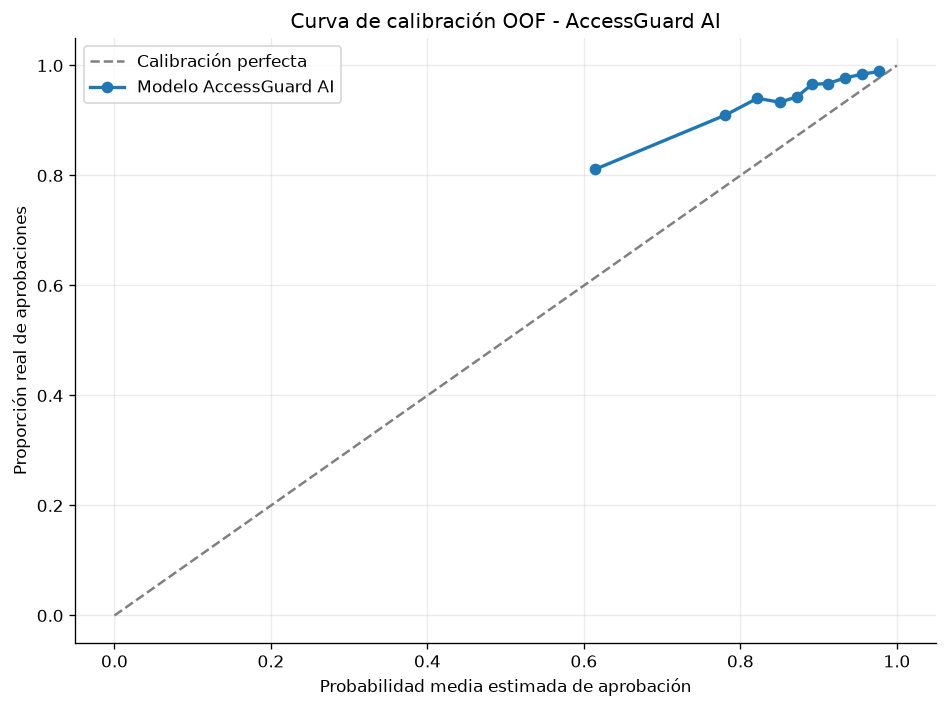


Gráfica guardada: /workspaces/laboratorio-avanzado-iam/reports/figures/calibration_curve_oof.png
Tabla guardada: /workspaces/laboratorio-avanzado-iam/reports/07_calibration_bins.csv


In [21]:
# ============================================================
# 14. CALIBRACIÓN DE PROBABILIDADES OOF
# ============================================================

from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.calibration import calibration_curve

# Métricas de calibración
brier = brier_score_loss(y_train, oof_prob)
baseline_prob = np.full(len(y_train), y_train.mean())
baseline_brier = brier_score_loss(y_train, baseline_prob)

brier_skill = 1 - (brier / baseline_brier)

roc_auc_oof = roc_auc_score(y_train, oof_prob)
logloss_oof = log_loss(y_train, oof_prob)

# Agrupar las probabilidades en diez grupos de tamaño similar
calibration_data = oof_results.copy()

calibration_data["grupo"] = pd.qcut(
    calibration_data["probabilidad_aprobacion"],
    q=10,
    duplicates="drop"
)

calibration_table = (
    calibration_data
    .groupby("grupo", observed=True)
    .agg(
        solicitudes=("ACTION", "size"),
        probabilidad_media=("probabilidad_aprobacion", "mean"),
        aprobacion_observada=("ACTION", "mean")
    )
    .reset_index()
)

# Diferencia entre lo estimado y lo observado
calibration_table["diferencia_absoluta"] = (
    calibration_table["probabilidad_media"]
    - calibration_table["aprobacion_observada"]
).abs()

# Error de calibración promedio ponderado por el tamaño de cada grupo
ece = np.average(
    calibration_table["diferencia_absoluta"],
    weights=calibration_table["solicitudes"]
)

# Mostrar resultados
print("MÉTRICAS DE VALIDACIÓN Y CALIBRACIÓN OOF")
print("----------------------------------------")
print(f"Brier Score: {brier:.6f}")
print(f"Brier baseline: {baseline_brier:.6f}")
print(f"Brier Skill Score: {brier_skill:.6f}")
print(f"Log Loss: {logloss_oof:.6f}")
print(f"ROC-AUC OOF: {roc_auc_oof:.6f}")
print(f"Error de calibración ponderado (ECE): {ece:.6f}")

print("\nTABLA DE CALIBRACIÓN")
display(calibration_table.round(4))

# Gráfica de calibración
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Calibración perfecta"
)

ax.plot(
    calibration_table["probabilidad_media"],
    calibration_table["aprobacion_observada"],
    marker="o",
    linewidth=2,
    label="Modelo AccessGuard AI"
)

ax.set_xlabel("Probabilidad media estimada de aprobación")
ax.set_ylabel("Proporción real de aprobaciones")
ax.set_title("Curva de calibración OOF - AccessGuard AI")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "calibration_curve_oof.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Guardar tabla
calibration_table.to_csv(
    REPORTS_DIR / "07_calibration_bins.csv",
    index=False
)

print("\nGráfica guardada:", FIGURES_DIR / "calibration_curve_oof.png")
print("Tabla guardada:", REPORTS_DIR / "07_calibration_bins.csv")

## 15. Análisis de calibración del modelo

La calibración permite analizar qué tan cercanas son las probabilidades estimadas por el modelo a las proporciones reales de aprobación.

Para esta evaluación se utilizaron predicciones fuera de muestra (OOF), mediante cinco pliegues de validación cruzada agrupados por gerente (`MGR_ID`).

### Resultados obtenidos

- ROC-AUC: 0.7291.
- Brier Score: 0.0608.
- Brier baseline: 0.0546.
- Brier Skill Score: -0.1144.
- Log Loss: 0.2375.
- ECE: 0.0812.

### Interpretación

La curva de calibración muestra que las proporciones reales de aprobación fueron superiores a las probabilidades promedio estimadas por el modelo en los diez grupos analizados.

Esto indica una tendencia del modelo a subestimar la probabilidad de aprobación.

Adicionalmente, el Brier Score del modelo fue superior al valor de referencia basado en la tasa global de aprobación. Su Brier Skill Score negativo indica que no logró superar esta predicción de referencia en términos de error cuadrático.

Aunque el ROC-AUC de 0.7291 muestra capacidad para diferenciar solicitudes, esto no significa que sus probabilidades estén correctamente calibradas.

### Conclusión

Los resultados evidencian que el modelo presenta capacidad de discriminación, pero tiene oportunidades de mejora en la calibración de sus probabilidades.

Se recomienda evaluar técnicas de calibración como Platt Scaling o Isotonic Regression en una etapa posterior, utilizando un procedimiento de validación independiente y sin modificar los resultados de evaluación previamente obtenidos.

En este análisis no se modificaron los hiperparámetros, el modelo ni el umbral de decisión establecido.

In [23]:
# ============================================================
# 16. ACTUALIZACIÓN DEL INFORME CON CALIBRACIÓN
# ============================================================

# Incorporar resultados de validación OOF
shap_report["validation_oof"] = {
    "method": "StratifiedGroupKFold",
    "folds": 5,
    "group_column": "MGR_ID",
    "seed": S.SEED,
    "requests": int(len(oof_results)),
    "roc_auc": float(roc_auc_oof)
}

# Incorporar métricas de calibración
shap_report["calibration"] = {
    "brier_score": float(brier),
    "brier_baseline": float(baseline_brier),
    "brier_skill_score": float(brier_skill),
    "log_loss": float(logloss_oof),
    "ece": float(ece),
    "interpretation": (
        "Las aprobaciones observadas fueron superiores a las "
        "probabilidades estimadas en los diez grupos analizados. "
        "El Brier Skill Score negativo indica que el modelo no "
        "superó la referencia basada en la tasa global de aprobación."
    ),
    "recommendation": (
        "Evaluar técnicas de calibración en una etapa posterior, "
        "mediante validación independiente."
    )
}

# Actualizar lista de resultados
shap_report["artifacts"]["calibration_curve"] = (
    "reports/figures/calibration_curve_oof.png"
)

shap_report["artifacts"]["calibration_table"] = (
    "reports/07_calibration_bins.csv"
)

# Guardar informe actualizado
with open(
    REPORTS_DIR / "07_shap_analysis.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(shap_report, file, indent=4, ensure_ascii=False)

print("INFORME ACTUALIZADO")
print("-------------------")
print("ROC-AUC OOF:", round(roc_auc_oof, 4))
print("Brier Score:", round(brier, 4))
print("Brier Skill Score:", round(brier_skill, 4))
print("ECE:", round(ece, 4))
print("\nJSON actualizado correctamente.")

INFORME ACTUALIZADO
-------------------
ROC-AUC OOF: 0.7291
Brier Score: 0.0608
Brier Skill Score: -0.1144
ECE: 0.0812

JSON actualizado correctamente.


In [24]:
# Verificación final de entregables

final_files = [
    ROOT / "notebooks/07_explicabilidad_shap_validacion.ipynb",
    REPORTS_DIR / "07_shap_analysis.json",
    REPORTS_DIR / "07_shap_importance.csv",
    REPORTS_DIR / "07_shap_direction.csv",
    REPORTS_DIR / "07_calibration_bins.csv",
    FIGURES_DIR / "shap_summary.png",
    FIGURES_DIR / "shap_importance.png",
    FIGURES_DIR / "calibration_curve_oof.png"
]

for file in final_files:
    print(
        ("OK" if file.exists() else "FALTA"),
        str(file.relative_to(ROOT))
    )

assert all(file.exists() for file in final_files)

print("\nTODOS LOS ENTREGABLES ESTÁN PRESENTES.")

OK notebooks/07_explicabilidad_shap_validacion.ipynb
OK reports/07_shap_analysis.json
OK reports/07_shap_importance.csv
OK reports/07_shap_direction.csv
OK reports/07_calibration_bins.csv
OK reports/figures/shap_summary.png
OK reports/figures/shap_importance.png
OK reports/figures/calibration_curve_oof.png

TODOS LOS ENTREGABLES ESTÁN PRESENTES.
